In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import ( accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)
import joblib

## Data Cleaning 

In [2]:
df = pd.read_csv("hotel_bookings.csv")

In [3]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
df.shape

(119390, 32)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [6]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [7]:
df.duplicated().sum()

31994

In [8]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.duplicated().sum()

0

In [11]:
df.drop(columns=['company'], inplace=True)

In [12]:
df['children'].fillna(df['children'].median(), inplace=True)
df['country'].fillna('Unknown', inplace=True)
df['agent'].fillna(-1, inplace=True)

C:\Users\salma\AppData\Local\Temp\ipykernel_2092\2994283096.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['children'].fillna(df['children'].median(), inplace=True)
C:\Users\salma\AppData\Local\Temp\ipykernel_2092\2994283096.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy

In [13]:
print(df.isnull().sum().sum())

0


In [14]:
df.shape

(87396, 31)

## EDA

In [15]:
df['is_canceled'].value_counts()

is_canceled
0    63371
1    24025
Name: count, dtype: int64

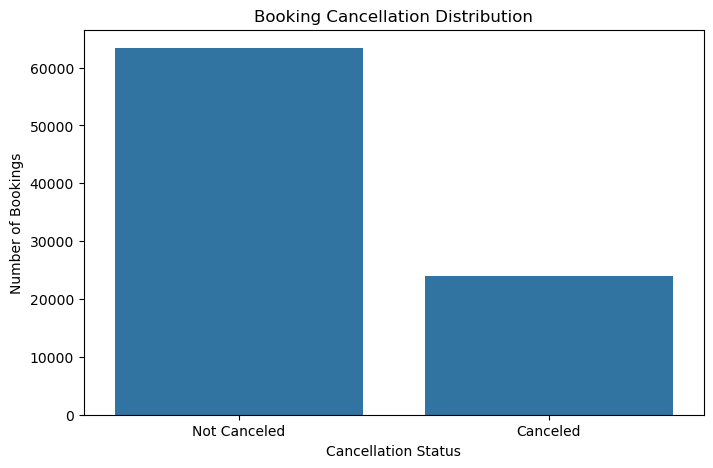

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='is_canceled')

plt.title('Booking Cancellation Distribution')
plt.xlabel('Cancellation Status')
plt.ylabel('Number of Bookings')

plt.xticks([0, 1], ['Not Canceled', 'Canceled'])

plt.show()

In [17]:
df['hotel'].value_counts()

hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: int64

In [18]:
df.groupby('hotel')['is_canceled'].mean() 

hotel
City Hotel      0.300386
Resort Hotel    0.234809
Name: is_canceled, dtype: float64

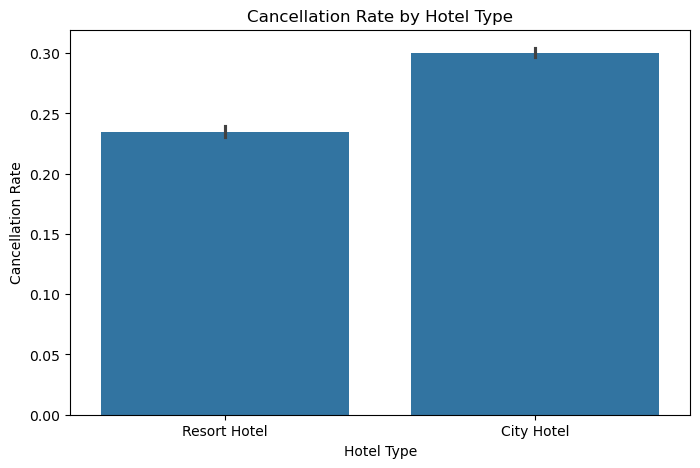

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x='hotel', y='is_canceled')

plt.title('Cancellation Rate by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate')

plt.show()

In [20]:
hotel_analysis = df.groupby('hotel').agg(
    Total_Bookings=('is_canceled', 'count'),
    Canceled_Bookings=('is_canceled', 'sum'),
    Cancellation_Rate=('is_canceled', 'mean')
)

hotel_analysis['Cancellation_Rate'] *= 100

hotel_analysis

,Total_Bookings,Canceled_Bookings,Cancellation_Rate
hotel,,,
City Hotel,53428,16049,30.038557
Resort Hotel,33968,7976,23.480923


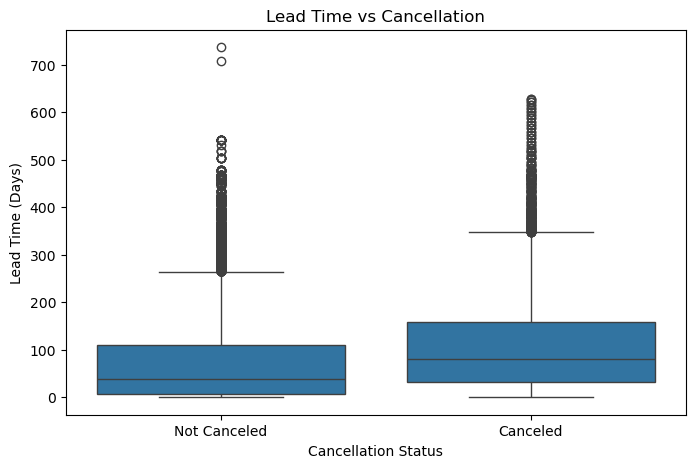

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='is_canceled', y='lead_time')

plt.title('Lead Time vs Cancellation')
plt.xlabel('Cancellation Status')
plt.ylabel('Lead Time (Days)')
plt.xticks([0, 1], ['Not Canceled', 'Canceled'])

plt.show()

# Deposit Type vs Cancellation

In [22]:
df.groupby('deposit_type')['is_canceled'].mean() 

deposit_type
No Deposit    0.266849
Non Refund    0.947013
Refundable    0.242991
Name: is_canceled, dtype: float64

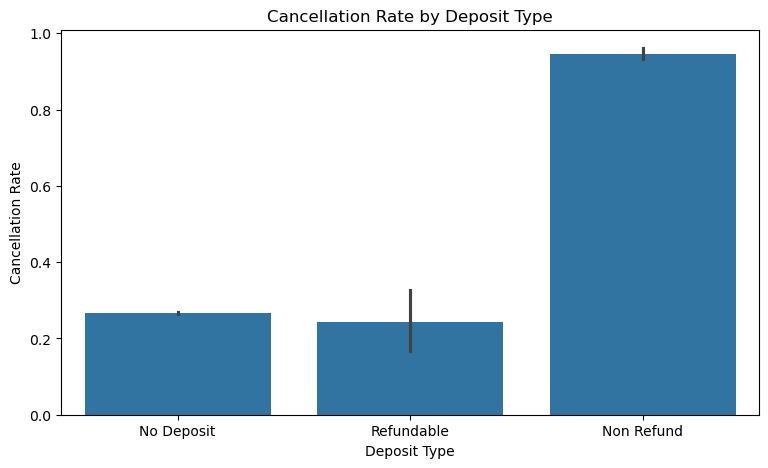

In [23]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='deposit_type',
    y='is_canceled'
)

plt.title('Cancellation Rate by Deposit Type')
plt.xlabel('Deposit Type')
plt.ylabel('Cancellation Rate')

plt.show()

In [24]:
deposit_analysis = df.groupby('deposit_type').agg(
    Total_Bookings=('is_canceled', 'count'),
    Canceled_Bookings=('is_canceled', 'sum'),
    Cancellation_Rate=('is_canceled', 'mean')
)

deposit_analysis['Cancellation_Rate'] *= 100

deposit_analysis

,Total_Bookings,Canceled_Bookings,Cancellation_Rate
deposit_type,,,
No Deposit,86251,23016,26.684908
Non Refund,1038,983,94.701349
Refundable,107,26,24.299065


# Market Segment vs Cancellation

In [25]:
df.groupby('market_segment')['is_canceled'].mean() 

market_segment
Aviation         0.198238
Complementary    0.125356
Corporate        0.121083
Direct           0.147154
Groups           0.270134
Offline TA/TO    0.148535
Online TA        0.353462
Undefined        1.000000
Name: is_canceled, dtype: float64

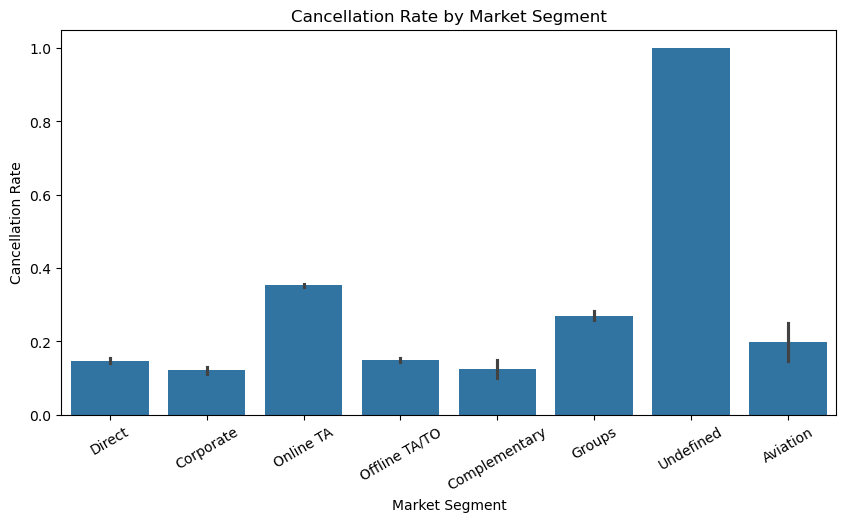

In [26]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='market_segment',
    y='is_canceled'
)

plt.title('Cancellation Rate by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Cancellation Rate')

plt.xticks(rotation=30)

plt.show()

In [27]:
market_analysis = df.groupby('market_segment').agg(
    Total_Bookings=('is_canceled', 'count'),
    Canceled_Bookings=('is_canceled', 'sum'),
    Cancellation_Rate=('is_canceled', 'mean')
)

market_analysis['Cancellation_Rate'] *= 100

market_analysis.sort_values(
    by='Cancellation_Rate',
    ascending=False
)

,Total_Bookings,Canceled_Bookings,Cancellation_Rate
market_segment,,,
Undefined,2,2,100.000000
Online TA,51618,18245,35.346197
Groups,4942,1335,27.013355
Aviation,227,45,19.823789
Offline TA/TO,13889,2063,14.853481
Direct,11804,1737,14.715351
Complementary,702,88,12.535613
Corporate,4212,510,12.108262


# Customer Type vs Cancellation

In [28]:
df.groupby('customer_type')['is_canceled'].mean() 

customer_type
Contract           0.163109
Group              0.099265
Transient          0.301059
Transient-Party    0.152383
Name: is_canceled, dtype: float64

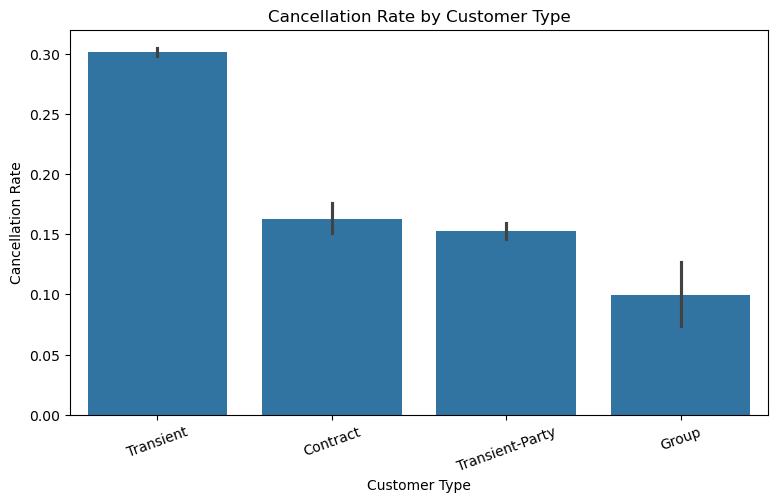

In [29]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='customer_type',
    y='is_canceled'
)

plt.title('Cancellation Rate by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Cancellation Rate')

plt.xticks(rotation=20)

plt.show()

In [30]:
customer_analysis = df.groupby('customer_type').agg(
    Total_Bookings=('is_canceled', 'count'),
    Canceled_Bookings=('is_canceled', 'sum'),
    Cancellation_Rate=('is_canceled', 'mean')
)

customer_analysis['Cancellation_Rate'] *= 100

customer_analysis.sort_values(
    by='Cancellation_Rate',
    ascending=False
)

,Total_Bookings,Canceled_Bookings,Cancellation_Rate
customer_type,,,
Transient,71986,21672,30.105854
Contract,3139,512,16.310927
Transient-Party,11727,1787,15.238339
Group,544,54,9.926471


# Special Requests vs Cancellation

In [31]:
df.groupby('total_of_special_requests')['is_canceled'].mean() 

total_of_special_requests
0    0.332027
1    0.224110
2    0.212919
3    0.171342
4    0.106250
5    0.055556
Name: is_canceled, dtype: float64

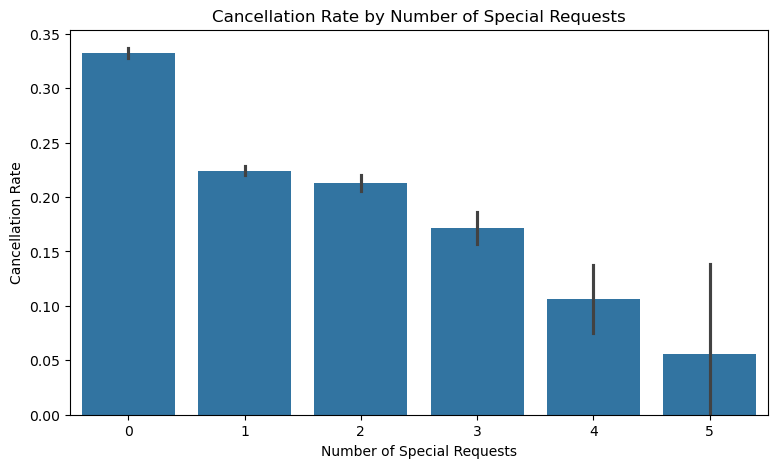

In [32]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='total_of_special_requests',
    y='is_canceled'
)

plt.title('Cancellation Rate by Number of Special Requests')
plt.xlabel('Number of Special Requests')
plt.ylabel('Cancellation Rate')

plt.show()

In [33]:
requests_analysis = df.groupby('total_of_special_requests').agg(
    Total_Bookings=('is_canceled', 'count'),
    Canceled_Bookings=('is_canceled', 'sum'),
    Cancellation_Rate=('is_canceled', 'mean')
)

requests_analysis['Cancellation_Rate'] *= 100

requests_analysis

,Total_Bookings,Canceled_Bookings,Cancellation_Rate
total_of_special_requests,,,
0,43894,14574,33.202716
1,29017,6503,22.411000
2,11812,2515,21.291907
3,2317,397,17.134225
4,320,34,10.625000
5,36,2,5.555556


# Previous Cancellations

In [34]:
df.groupby('previous_cancellations')['is_canceled'].mean()

previous_cancellations
0     0.266955
1     0.761194
2     0.303571
3     0.262295
4     0.200000
5     0.105263
6     0.117647
11    0.074074
13    0.750000
14    1.000000
19    1.000000
21    1.000000
24    1.000000
25    1.000000
26    1.000000
Name: is_canceled, dtype: float64

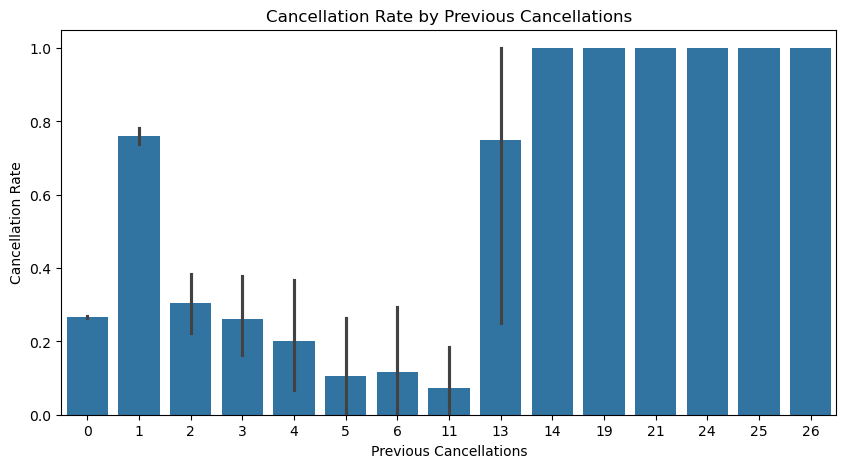

In [35]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='previous_cancellations',
    y='is_canceled'
)

plt.title('Cancellation Rate by Previous Cancellations')
plt.xlabel('Previous Cancellations')
plt.ylabel('Cancellation Rate')

plt.show()

In [36]:
previous_analysis = df.groupby('previous_cancellations').agg(
    Total_Bookings=('is_canceled', 'count'),
    Canceled_Bookings=('is_canceled', 'sum'),
    Cancellation_Rate=('is_canceled', 'mean')
)

previous_analysis['Cancellation_Rate'] *= 100

previous_analysis

,Total_Bookings,Canceled_Bookings,Cancellation_Rate
previous_cancellations,,,
0,85711,22881,26.695523
1,1407,1071,76.119403
2,112,34,30.357143
3,61,16,26.229508
4,30,6,20.000000
5,19,2,10.526316
6,17,2,11.764706
11,27,2,7.407407
13,4,3,75.000000


In [37]:
df['previous_cancellations_group'] = np.where(
    df['previous_cancellations'] == 0,
    '0',
    np.where(
        df['previous_cancellations'] == 1,
        '1',
        '2+'
    )
)

In [38]:
previous_group_analysis = df.groupby(
    'previous_cancellations_group'
).agg(
    Total_Bookings=('is_canceled', 'count'),
    Canceled_Bookings=('is_canceled', 'sum'),
    Cancellation_Rate=('is_canceled', 'mean')
)

previous_group_analysis['Cancellation_Rate'] *= 100

previous_group_analysis

,Total_Bookings,Canceled_Bookings,Cancellation_Rate
previous_cancellations_group,,,
0,85711,22881,26.695523
1,1407,1071,76.119403
2+,278,73,26.258993


## Feature Engineering & Data Preprocessing

In [39]:
df.columns.tolist()

['hotel',
 'is_canceled',
 'lead_time',
 'arrival_date_year',
 'arrival_date_month',
 'arrival_date_week_number',
 'arrival_date_day_of_month',
 'stays_in_weekend_nights',
 'stays_in_week_nights',
 'adults',
 'children',
 'babies',
 'meal',
 'country',
 'market_segment',
 'distribution_channel',
 'is_repeated_guest',
 'previous_cancellations',
 'previous_bookings_not_canceled',
 'reserved_room_type',
 'assigned_room_type',
 'booking_changes',
 'deposit_type',
 'agent',
 'days_in_waiting_list',
 'customer_type',
 'adr',
 'required_car_parking_spaces',
 'total_of_special_requests',
 'reservation_status',
 'reservation_status_date',
 'previous_cancellations_group']

In [40]:
df.drop(
    columns=[
        'reservation_status',
        'reservation_status_date',
        'previous_cancellations_group',
        'assigned_room_type',
        'booking_changes'
    ],
    inplace=True
)

In [41]:
df.shape

(87396, 27)

In [42]:
df.dtypes

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
deposit_type                       object
agent                             float64
days_in_waiting_list                int64
customer_type                     

In [43]:
categorical_features = [
    'hotel',
    'arrival_date_month',
    'meal',
    'country',
    'market_segment',
    'distribution_channel',
    'reserved_room_type',
    'deposit_type',
    'customer_type',
    'agent'
]

In [44]:
df['agent'] = df['agent'].astype(str)

In [45]:
x = df.drop(columns=['is_canceled'])

y = df['is_canceled']

In [46]:
x_train , x_test , y_train , y_test = train_test_split(x , y , test_size= 0.2 , random_state=42 , stratify= y)

In [47]:
print("x_train:", x_train.shape)
print("x_test:", x_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

x_train: (69916, 26)
x_test: (17480, 26)
y_train: (69916,)
y_test: (17480,)


## Data Preprocessing

In [48]:
categorical_features = x_train.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = x_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

print("\nNumber of Categorical Features:",
      len(categorical_features))

print("\nNumber of Numerical Features:",
      len(numerical_features))

Categorical Features:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type']

Numerical Features:
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Number of Categorical Features: 10

Number of Numerical Features: 16


In [49]:
print("Missing values in X_train:",
      x_train.isnull().sum().sum())

print("Missing values in x_test:",
      x_test.isnull().sum().sum())

Missing values in X_train: 0
Missing values in x_test: 0


In [50]:
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [51]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [52]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [53]:
x_train_processed = preprocessor.fit_transform(x_train)

x_test_processed = preprocessor.transform(x_test)

print("x_train shape:", x_train_processed.shape)
print("x_test shape:", x_test_processed.shape)

x_train shape: (69916, 558)
x_test shape: (17480, 558)


## Logistic Regression

In [54]:
from sklearn.linear_model import LogisticRegression

In [55]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(x_train_processed, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [56]:
y_pred = logistic_model.predict(x_test_processed)

In [57]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.7967391304347826
Precision: 0.671978021978022
Recall: 0.5090530697190426
F1 Score: 0.5792776791000592


In [58]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.91      0.87     12675
           1       0.67      0.51      0.58      4805

    accuracy                           0.80     17480
   macro avg       0.75      0.71      0.72     17480
weighted avg       0.79      0.80      0.79     17480



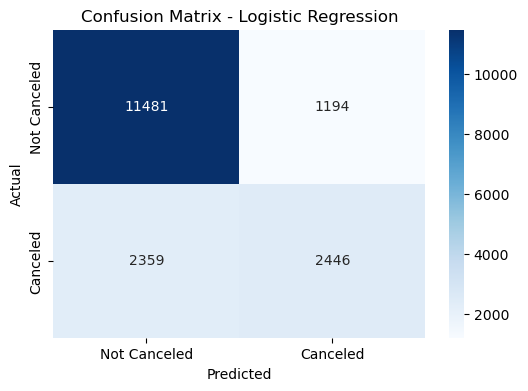

In [59]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Canceled', 'Canceled'],
    yticklabels=['Not Canceled', 'Canceled']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

## Random Forest Classification

In [60]:
from sklearn.ensemble import RandomForestClassifier

In [61]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

random_forest_model.fit(x_train_processed, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=15,
                       min_samples_leaf=4, min_samples_split=10, n_jobs=-1,
                       random_state=42)

In [62]:
y_pred_rf = random_forest_model.predict(x_test_processed)

In [63]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

Accuracy: 0.7537185354691075
Precision: 0.5328774329300369
Recall: 0.8432882414151925
F1 Score: 0.6530743814973003


In [64]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.92      0.72      0.81     12675
           1       0.53      0.84      0.65      4805

    accuracy                           0.75     17480
   macro avg       0.73      0.78      0.73     17480
weighted avg       0.82      0.75      0.77     17480



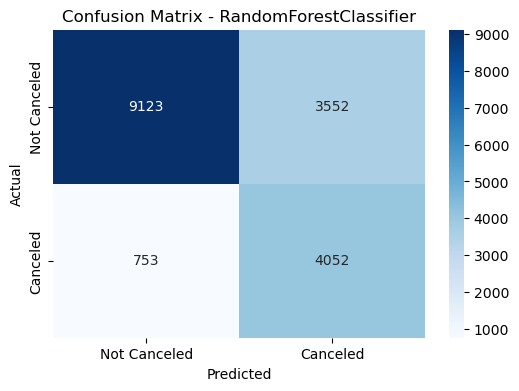

In [65]:
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Canceled', 'Canceled'],
    yticklabels=['Not Canceled', 'Canceled']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - RandomForestClassifier')
plt.show()

In [66]:
feature_importance = random_forest_model.feature_importances_

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

importance_df.head(15)

,Feature,Importance
165,cat__country_PRT,0.104533
0,num__lead_time,0.102315
14,num__required_car_parking_spaces,0.090885
212,cat__market_segment_Online TA,0.065340
544,cat__agent_9.0,0.056654
15,num__total_of_special_requests,0.051025
556,cat__customer_type_Transient,0.029465
13,num__adr,0.027992
10,num__previous_cancellations,0.027623
211,cat__market_segment_Offline TA/TO,0.027227


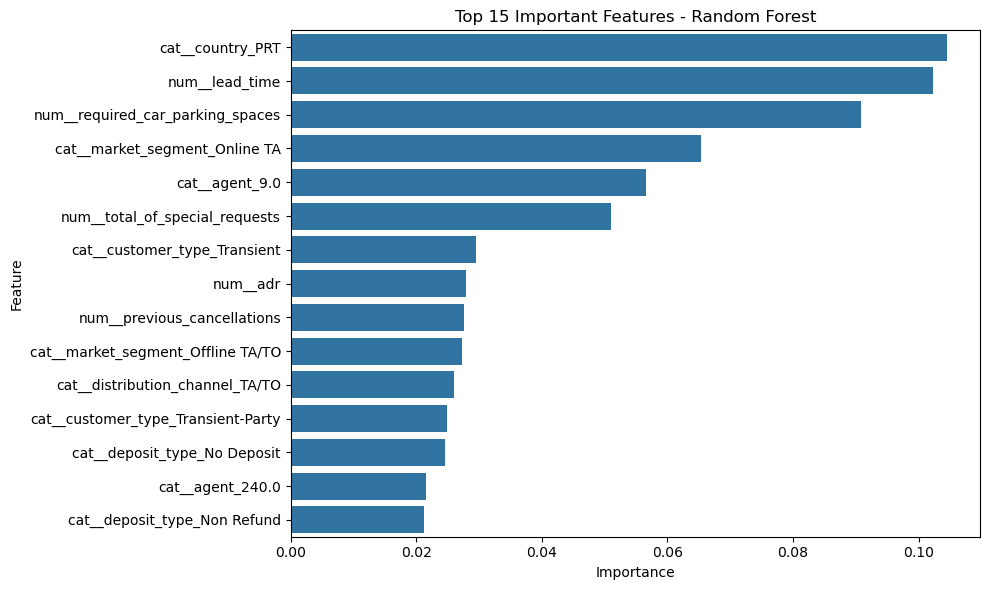

In [67]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Important Features - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [68]:
joblib.dump(random_forest_model, 'random_forest_model.pkl')
joblib.dump(logistic_model, 'logistic_regression_model.pkl')
joblib.dump(preprocessor, 'preprocessor.pkl')

['preprocessor.pkl']

In [69]:
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision': [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_rf)
    ],
    'Recall': [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_rf)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_rf)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.796739,0.671978,0.509053,0.579278
1,Random Forest,0.753719,0.532877,0.843288,0.653074


In [70]:
logistic_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

In [71]:
param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__solver': ['lbfgs', 'liblinear']
}

In [72]:
grid_search = GridSearchCV( estimator=logistic_pipeline, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1 )

In [73]:
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['lead_time',
                                                                          'arrival_date_year',
                                                                          'arrival_date_week_number',
                                                                          'arrival_date_day_of_month',
                                                                          'stays_in_weekend_nights',
                                                                          'stays_in_week_nights',
                                                                          'adults',
                                                                          'children',
                                                                          'ba...
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['hotel',
                                                                          'arrival_date_month',
                                                                          'meal',
                                                                          'country',
                                                                          'market_segment',
                                                                          'distribution_channel',
                                                                          'reserved_room_type',
                                                                          'deposit_type',
                                                                          'agent',
                                                                          'customer_type'])])),
                                       ('model',
                                        LogisticRegression(max_iter=1000,
                                                           random_state=42))]),
             n_jobs=-1,
             param_grid={'model__C': [0.01, 0.1, 1, 10, 100],
                         'model__solver': ['lbfgs', 'liblinear']},
             scoring='accuracy', verbose=1)

In [74]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'model__C': 10, 'model__solver': 'lbfgs'}
Best CV Accuracy: 0.7992876903402318


In [75]:
best_logistic_model = grid_search.best_estimator_

y_pred_tuned = best_logistic_model.predict(x_test)

print("Tuned Model Test Accuracy:",
      accuracy_score(y_test, y_pred_tuned))

print("Tuned Model Precision:",
      precision_score(y_test, y_pred_tuned))

print("Tuned Model Recall:",
      recall_score(y_test, y_pred_tuned))

print("Tuned Model F1 Score:",
      f1_score(y_test, y_pred_tuned))

Tuned Model Test Accuracy: 0.7959382151029748
Tuned Model Precision: 0.6695890410958905
Tuned Model Recall: 0.508636836628512
Tuned Model F1 Score: 0.5781194559432289


In [76]:
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 15, 20],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [2, 4],
    'class_weight': ['balanced']
}

In [77]:
rf_grid_search = GridSearchCV(estimator=RandomForestClassifier(random_state=42, n_jobs=-1), param_grid=rf_param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)

In [78]:
rf_grid_search.fit(x_train_processed, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'class_weight': ['balanced'],
                         'max_depth': [10, 15, 20], 'min_samples_leaf': [2, 4],
                         'min_samples_split': [5, 10],
                         'n_estimators': [100, 200]},
             scoring='accuracy', verbose=1)

In [79]:
print("Best Parameters:", rf_grid_search.best_params_)
print("Best CV Accuracy:", rf_grid_search.best_score_)

Best Parameters: {'class_weight': 'balanced', 'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 200}
Best CV Accuracy: 0.776074102772065


In [80]:
best_rf_model = rf_grid_search.best_estimator_

y_pred_rf_tuned = best_rf_model.predict(x_test_processed)

print("Tuned Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf_tuned))

print("Tuned Random Forest Precision:",
      precision_score(y_test, y_pred_rf_tuned))

print("Tuned Random Forest Recall:",
      recall_score(y_test, y_pred_rf_tuned))

print("Tuned Random Forest F1:",
      f1_score(y_test, y_pred_rf_tuned))

Tuned Random Forest Accuracy: 0.7712814645308924
Tuned Random Forest Precision: 0.554682206261011
Tuned Random Forest Recall: 0.8518210197710718
Tuned Random Forest F1: 0.6718647406434668


In [81]:
comparison_df = pd.DataFrame({
    'Model': [
        'Logistic Regression - Before Tuning',
        'Logistic Regression - After Tuning',
        'Random Forest - Before Tuning',
        'Random Forest - After Tuning'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_tuned),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_rf_tuned)
    ],

    'Precision': [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_tuned),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf_tuned)
    ],

    'Recall': [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_tuned),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf_tuned)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_tuned),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf_tuned)
    ]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression - Before Tuning,0.796739,0.671978,0.509053,0.579278
1,Logistic Regression - After Tuning,0.795938,0.669589,0.508637,0.578119
2,Random Forest - Before Tuning,0.753719,0.532877,0.843288,0.653074
3,Random Forest - After Tuning,0.771281,0.554682,0.851821,0.671865


              precision    recall  f1-score   support

           0       0.93      0.74      0.82     12675
           1       0.55      0.85      0.67      4805

    accuracy                           0.77     17480
   macro avg       0.74      0.80      0.75     17480
weighted avg       0.83      0.77      0.78     17480



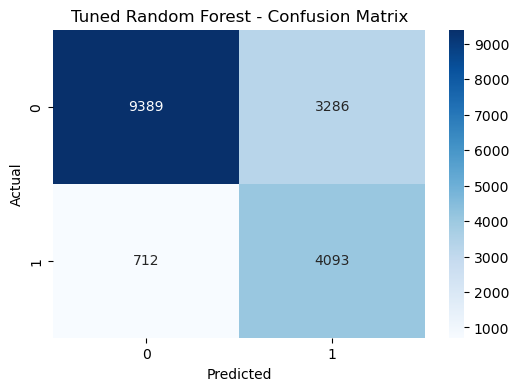

In [82]:
print(classification_report(y_test, y_pred_rf_tuned))

cm = confusion_matrix(y_test, y_pred_rf_tuned)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Tuned Random Forest - Confusion Matrix')
plt.show()

In [85]:
x_test_processed = preprocessor.transform(x_test)


In [86]:
y_prob_rf = best_rf_model.predict_proba(x_test_processed)[:, 1]


In [87]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)
roc_auc = roc_auc_score(y_test, y_prob_rf)

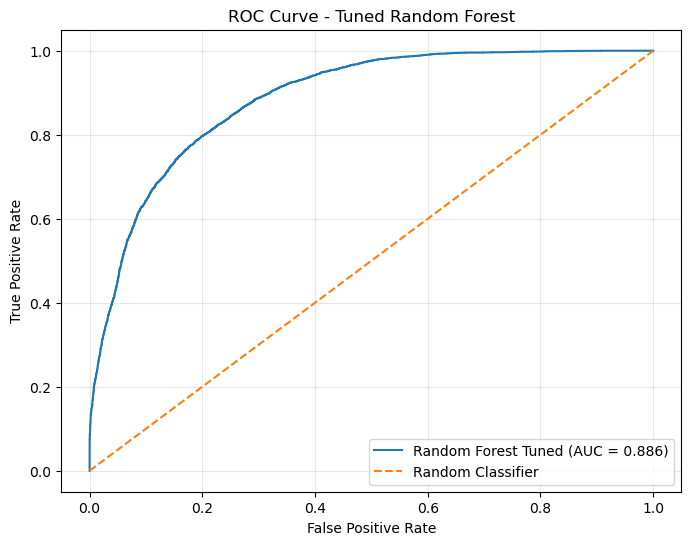

Random Forest Tuned ROC-AUC: 0.8862264858064106


In [88]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Random Forest Tuned (AUC = {roc_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Random Forest Tuned ROC-AUC:", roc_auc)

In [92]:
logistic_probs = logistic_model.predict_proba(x_test_processed)[:, 1]
rf_probs = best_rf_model.predict_proba(x_test_processed)[:, 1]

In [93]:
auc_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest Tuned"
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, logistic_probs),
        roc_auc_score(y_test, rf_probs)
    ]
})

print(auc_comparison)

                 Model   ROC-AUC
0  Logistic Regression  0.855448
1  Random Forest Tuned  0.886226


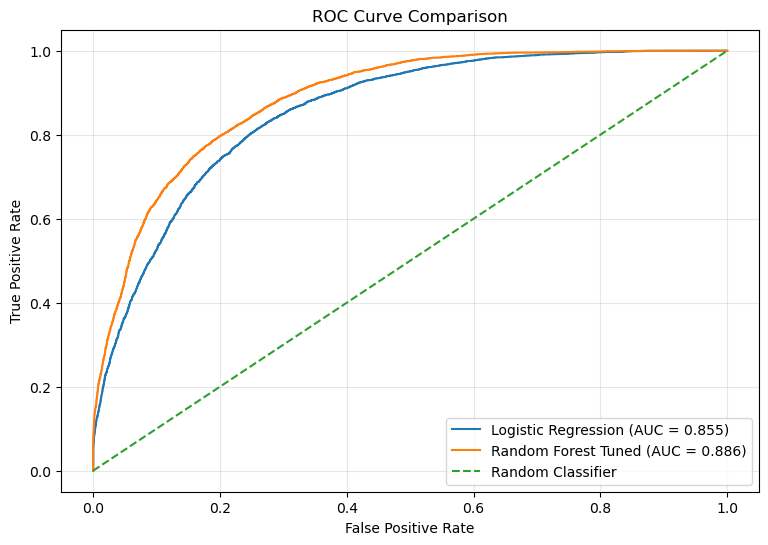

In [94]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, logistic_probs)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)

plt.figure(figsize=(9, 6))

plt.plot(
    fpr_lr, tpr_lr,
    label='Logistic Regression (AUC = 0.855)'
)

plt.plot(
    fpr_rf, tpr_rf,
    label='Random Forest Tuned (AUC = 0.886)'
)

plt.plot(
    [0, 1], [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [97]:
joblib.dump(best_rf_model, "random_forest_tuned.pkl")

joblib.dump(preprocessor, "preprocessor.pkl")

print("Final model and preprocessor saved successfully!")

Final model and preprocessor saved successfully!
